# Cuffless AI — PPG Feature Extraction

This notebook splits every recording in the four dataset files into five-second windows and extracts PPG features from each window. It also derives SBP and DBP labels from the ABP signal and a blood pressure category. Noisy or physiologically impossible windows are discarded. The output is `data/ppg_features.csv`, with one row per window.

## 1. Imports

In [1]:
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, find_peaks
from scipy.stats import skew, kurtosis

## 2. Locate all four files

In [2]:
data_files = [
    Path("../data/Part_1.mat"),
    Path("../data/Part_2.mat"),
    Path("../data/Part_3.mat"),
    Path("../data/Part_4.mat"),
]
output_file = Path("../data/ppg_features.csv")

for filename in data_files:
    print(filename.name, "exists:", filename.exists())

if not all(filename.exists() for filename in data_files):
    raise FileNotFoundError("Put all four Part_*.mat files inside the data/ folder.")

Part_1.mat exists: True
Part_2.mat exists: True
Part_3.mat exists: True
Part_4.mat exists: True


## 3. Settings

In [3]:
FS = 125
WINDOW_SECONDS = 5
WINDOW_SAMPLES = FS * WINDOW_SECONDS
MIN_PEAK_DISTANCE = int(0.33 * FS)  # max ~180 bpm
MAX_RECORDS = None  # set to a small number for a quick test run

print("Samples per five-second window:", WINDOW_SAMPLES)

Samples per five-second window: 625


## 4. Filter the PPG and detect beats

The PPG is band-pass filtered (0.5–8 Hz) to remove baseline drift and high-frequency noise. Each beat is located by its peak and its foot, which is the minimum between two consecutive peaks. Only complete beats (foot, peak, next foot) are used.

In [4]:
def bandpass(signal, low=0.5, high=8.0, fs=FS, order=3):
    b, a = butter(order, [low, high], btype="band", fs=fs)
    return filtfilt(b, a, signal)


def find_beats(ppg):
    peaks, _ = find_peaks(ppg, distance=MIN_PEAK_DISTANCE, prominence=0.3 * np.std(ppg))
    beats = []
    for k in range(1, len(peaks) - 1):
        foot = peaks[k - 1] + np.argmin(ppg[peaks[k - 1]:peaks[k]])
        next_foot = peaks[k] + np.argmin(ppg[peaks[k]:peaks[k + 1]])
        beats.append((foot, peaks[k], next_foot))
    return peaks, beats

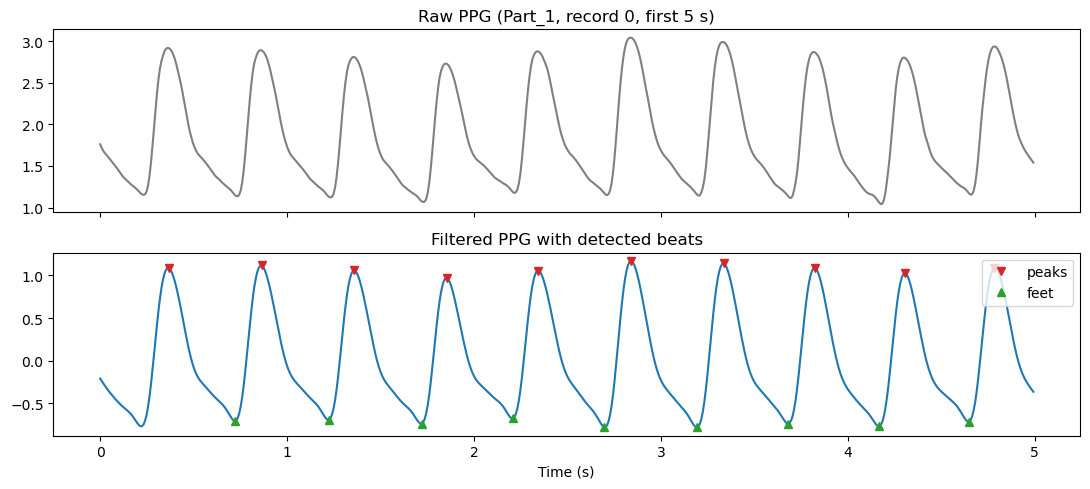

In [5]:
with h5py.File(data_files[0], "r") as f:
    example = f[f["Part_1"][0, 0]][:]

ppg_raw = example[:WINDOW_SAMPLES, 0]
ppg_clean = bandpass(example[:, 0])[:WINDOW_SAMPLES]
peaks, beats = find_beats(ppg_clean)
feet = sorted({b[0] for b in beats} | {b[2] for b in beats})

t = np.arange(WINDOW_SAMPLES) / FS
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(t, ppg_raw, color="gray")
axes[0].set_title("Raw PPG (Part_1, record 0, first 5 s)")
axes[1].plot(t, ppg_clean)
axes[1].plot(t[peaks], ppg_clean[peaks], "v", color="tab:red", label="peaks")
axes[1].plot(t[feet], ppg_clean[feet], "^", color="tab:green", label="feet")
axes[1].set_title("Filtered PPG with detected beats")
axes[1].set_xlabel("Time (s)")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

## 5. PPG features

Per-beat features are averaged over the complete beats in the window.

| Feature | Description |
|---|---|
| `heart_rate_bpm` | beats per minute |
| `hrv_std_ms` | standard deviation of the time between peaks |
| `pulse_height` | foot-to-peak amplitude |
| `rise_time_s` | time from foot to peak |
| `fall_time_s` | time from peak to next foot |
| `rise_fall_ratio` | rise time / fall time |
| `pulse_width_s` | time above half the pulse height |
| `max_upslope` | steepest slope between foot and peak |
| `ppg_mean` | mean of the raw PPG |
| `ppg_std`, `ppg_min`, `ppg_max`, `ppg_range` | statistics of the filtered PPG |
| `ppg_skewness`, `ppg_kurtosis` | shape of the filtered PPG distribution |

In [6]:
def extract_ppg_features(ppg_window, ppg_raw_window):
    peaks, beats = find_beats(ppg_window)
    if len(beats) < 2:
        return None

    rise, fall, height, width, upslope = [], [], [], [], []
    for foot, peak, next_foot in beats:
        h = ppg_window[peak] - ppg_window[foot]
        rise.append((peak - foot) / FS)
        fall.append((next_foot - peak) / FS)
        height.append(h)
        width.append(np.sum(ppg_window[foot:next_foot + 1] >= ppg_window[foot] + 0.5 * h) / FS)
        upslope.append(np.max(np.diff(ppg_window[foot:peak + 1])) * FS)

    intervals = np.diff(peaks) / FS
    rise, fall = np.array(rise), np.array(fall)

    return {
        "heart_rate_bpm": 60 / np.mean(intervals),
        "hrv_std_ms": np.std(intervals) * 1000,
        "pulse_height": np.mean(height),
        "rise_time_s": np.mean(rise),
        "fall_time_s": np.mean(fall),
        "rise_fall_ratio": np.mean(rise / fall),
        "pulse_width_s": np.mean(width),
        "max_upslope": np.mean(upslope),
        "ppg_mean": np.mean(ppg_raw_window),
        "ppg_std": np.std(ppg_window),
        "ppg_min": np.min(ppg_window),
        "ppg_max": np.max(ppg_window),
        "ppg_range": np.ptp(ppg_window),
        "ppg_skewness": skew(ppg_window),
        "ppg_kurtosis": kurtosis(ppg_window),
        "n_beats": len(beats),
    }


pd.Series(extract_ppg_features(ppg_clean, ppg_raw)).round(3)

heart_rate_bpm     122.283
hrv_std_ms           6.532
pulse_height         1.814
rise_time_s          0.140
fall_time_s          0.351
rise_fall_ratio      0.399
pulse_width_s        0.174
max_upslope         22.565
ppg_mean             1.842
ppg_std              0.598
ppg_min             -0.782
ppg_max              1.170
ppg_range            1.952
ppg_skewness         0.566
ppg_kurtosis        -1.101
n_beats              8.000
dtype: float64

## 6. SBP and DBP labels

SBP is the mean of the ABP peaks and DBP is the mean of the ABP valleys in the window.

In [7]:
def extract_bp_labels(abp_window):
    peaks, _ = find_peaks(abp_window, distance=MIN_PEAK_DISTANCE, prominence=10)
    valleys, _ = find_peaks(-abp_window, distance=MIN_PEAK_DISTANCE, prominence=10)
    if len(peaks) < 2 or len(valleys) < 2:
        return None
    return {"sbp": np.mean(abp_window[peaks]), "dbp": np.mean(abp_window[valleys])}


extract_bp_labels(example[:WINDOW_SAMPLES, 1])

{'sbp': np.float64(121.548553481852), 'dbp': np.float64(66.9652669574519)}

## 7. Window quality checks

A window is discarded if the PPG is clipped at the sensor limits (0 or 4), if the PPG or ABP is flat, if there are fewer than two complete beats, or if the values are physiologically implausible.

In [8]:
def window_is_clean(ppg_raw_window, abp_window):
    clipped = np.mean((ppg_raw_window <= 0.01) | (ppg_raw_window >= 3.99)) > 0.01
    flat_ppg = np.std(ppg_raw_window) < 0.01
    flat_abp = np.ptp(abp_window) < 10
    return not (clipped or flat_ppg or flat_abp)


def features_are_plausible(feats, labels):
    return (
        40 <= feats["heart_rate_bpm"] <= 180
        and feats["hrv_std_ms"] < 200
        and 70 <= labels["sbp"] <= 200
        and 40 <= labels["dbp"] <= 120
        and labels["dbp"] < labels["sbp"]
    )

## 8. Process every recording

This loop reads one recording at a time from all four files and may take 15–20 minutes. Each row keeps its `file` and `record_index`, so windows from the same recording can stay in the same train/test split.

In [9]:
rows = []
skipped = {"bad_signal": 0, "too_few_beats": 0, "implausible": 0}

for filename in data_files:
    dataset_name = filename.stem

    with h5py.File(filename, "r") as f:
        recording_refs = f[dataset_name]
        num_records = recording_refs.shape[0] if MAX_RECORDS is None else MAX_RECORDS

        for record_index in range(num_records):
            record = f[recording_refs[record_index, 0]][:]
            if len(record) < 2 * WINDOW_SAMPLES:
                continue

            ppg_all_raw, abp_all = record[:, 0], record[:, 1]
            ppg_all_clean = bandpass(ppg_all_raw)

            for window_index in range(len(record) // WINDOW_SAMPLES):
                sl = slice(window_index * WINDOW_SAMPLES, (window_index + 1) * WINDOW_SAMPLES)

                if not window_is_clean(ppg_all_raw[sl], abp_all[sl]):
                    skipped["bad_signal"] += 1
                    continue

                feats = extract_ppg_features(ppg_all_clean[sl], ppg_all_raw[sl])
                labels = extract_bp_labels(abp_all[sl])
                if feats is None or labels is None:
                    skipped["too_few_beats"] += 1
                    continue

                if not features_are_plausible(feats, labels):
                    skipped["implausible"] += 1
                    continue

                rows.append({
                    "file": filename.name,
                    "record_index": record_index,
                    "window_index": window_index,
                    **feats,
                    **labels,
                })

    print(f"Finished {filename.name}")

df = pd.DataFrame(rows)
print("Windows kept:", len(df))
print("Windows skipped:", skipped)

Finished Part_1.mat


Finished Part_2.mat


Finished Part_3.mat


Finished Part_4.mat


Windows kept: 513554
Windows skipped: {'bad_signal': 5818, 'too_few_beats': 584, 'implausible': 7746}


In [10]:
df.groupby("file").agg(
    recordings=("record_index", "nunique"),
    windows=("window_index", "count"),
    mean_sbp=("sbp", "mean"),
    mean_dbp=("dbp", "mean"),
).round(1)

,recordings,windows,mean_sbp,mean_dbp
file,,,,
Part_1.mat,2705,127678,131.7,66.2
Part_2.mat,2785,147178,127.7,68.1
Part_3.mat,2679,109731,125.4,63.7
Part_4.mat,2690,128967,131.0,67.9


In [11]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
record_index,513554.0,1484.44,838.78,0.00,771.00,1474.00,2217.00,2999.00
window_index,513554.0,39.39,29.51,0.00,14.00,34.00,61.00,117.00
heart_rate_bpm,513554.0,90.87,17.19,42.29,78.29,90.21,101.18,180.00
hrv_std_ms,513554.0,27.24,39.42,0.00,5.57,8.84,25.58,200.00
pulse_height,513554.0,1.56,0.50,0.05,1.49,1.76,1.89,3.24
rise_time_s,513554.0,0.20,0.07,0.11,0.16,0.18,0.23,0.72
fall_time_s,513554.0,0.48,0.13,0.11,0.40,0.48,0.56,1.17
rise_fall_ratio,513554.0,0.50,0.36,0.13,0.32,0.37,0.49,3.63
pulse_width_s,513554.0,0.23,0.05,0.10,0.19,0.22,0.26,0.64
max_upslope,513554.0,16.41,5.68,0.58,14.38,17.83,20.41,41.06


## 9. Blood pressure category

The rules are checked in this order: **high** if SBP ≥ 130 or DBP ≥ 80; **low** if SBP < 90 or DBP < 60; **elevated** if SBP is 120–129; otherwise **normal**.

In [12]:
df["bp_category"] = np.select(
    [(df["sbp"] >= 130) | (df["dbp"] >= 80), (df["sbp"] < 90) | (df["dbp"] < 60), df["sbp"] >= 120],
    ["high", "low", "elevated"],
    default="normal",
)

df["bp_category"].value_counts()

bp_category
high        243897
low         132078
normal       81901
elevated     55678
Name: count, dtype: int64

## 10. Feature correlation with SBP and DBP

A quick check of which features move with blood pressure. Correlation looks at one feature at a time, so weak features can still help a model in combination.

In [13]:
feature_columns = [
    c for c in df.columns
    if c not in ("file", "record_index", "window_index", "n_beats", "sbp", "dbp", "bp_category")
]

corr = df[feature_columns + ["sbp", "dbp"]].corr()[["sbp", "dbp"]].drop(["sbp", "dbp"])
corr.reindex(corr["sbp"].abs().sort_values(ascending=False).index).round(2)

,sbp,dbp
fall_time_s,0.18,-0.11
rise_fall_ratio,-0.17,-0.01
ppg_kurtosis,-0.13,-0.07
heart_rate_bpm,-0.13,0.16
max_upslope,0.12,0.07
ppg_std,0.12,0.02
ppg_min,-0.11,-0.10
pulse_height,0.10,0.01
pulse_width_s,0.10,-0.02
rise_time_s,-0.10,-0.09


Takeaways:

- All correlations are weak (|r| ≤ 0.18). No single feature predicts blood pressure well on its own.
- For SBP, the strongest features are `fall_time_s`, `rise_fall_ratio`, `ppg_kurtosis` and `heart_rate_bpm`.
- For DBP, the strongest features are `heart_rate_bpm`, `fall_time_s`, `ppg_skewness` and `ppg_min`.
- `hrv_std_ms` shows almost no relationship with either label.
- `pulse_height`, `ppg_std`, `ppg_range` and `ppg_max` all measure pulse size, so they carry similar information.

Suggestion: train the first models on all 15 features, then compare against a smaller set.

## 11. Save the dataset

In [14]:
df.to_csv(output_file, index=False)
print(f"Saved {len(df)} rows to {output_file}")
df.head()

Saved 513554 rows to ../data/ppg_features.csv


,file,record_index,window_index,heart_rate_bpm,hrv_std_ms,pulse_height,rise_time_s,fall_time_s,rise_fall_ratio,pulse_width_s,...,ppg_std,ppg_min,ppg_max,ppg_range,ppg_skewness,ppg_kurtosis,n_beats,sbp,dbp,bp_category
0,Part_1.mat,0,0,122.282609,6.531973,1.813675,0.140000,0.351000,0.399019,0.174000,...,0.597956,-0.781994,1.170041,1.952035,0.565720,-1.100639,8,121.548553,66.965267,elevated
1,Part_1.mat,0,1,124.538745,3.325918,1.833584,0.141000,0.341000,0.413552,0.174000,...,0.610240,-0.839073,1.125238,1.964311,0.556218,-1.126886,8,124.698998,68.821343,elevated
2,Part_1.mat,0,2,123.558484,3.666061,1.840527,0.143111,0.342222,0.418236,0.175111,...,0.622769,-0.813614,1.174565,1.988180,0.473515,-1.229513,9,125.729609,69.495392,elevated
3,Part_1.mat,0,3,123.175182,4.532462,1.846716,0.140000,0.348000,0.402418,0.171000,...,0.608763,-0.875011,1.166518,2.041529,0.520074,-1.139393,8,122.168874,67.302291,elevated
4,Part_1.mat,0,4,124.309392,6.531973,1.873393,0.140000,0.342000,0.409522,0.173000,...,0.614460,-0.846043,1.148492,1.994535,0.565535,-1.101957,8,125.529348,69.334206,elevated
